<a href="https://colab.research.google.com/github/malakmagdy256/Machine-Learning/blob/main/ass_ml_sheet2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#sheet 2.1
import numpy as np

def mse(y, yhat):
    return np.mean((y - yhat) ** 2)

# Example data
y = np.array([1, 2, 3, 4])
yhat = np.array([1.2, 1.8, 3.1, 3.9])

training_mse = mse(y, yhat)

print("Training MSE:", training_mse)



Training MSE: 0.025


In [ ]:
#sheet 2.2
import numpy as np

# Training data: y = 0.5 + 1.1x
X = np.array([1, 2, 3, 4], dtype=float)
y = np.array([1.6, 2.7, 3.8, 4.9])

# Add bias column
X_b = np.c_[np.ones(len(X)), X]

# Initialize parameters
theta = np.zeros(2)

learning_rate = 0.05
iterations = 2000
m = len(y)

# Batch Gradient Descent
for i in range(iterations):
    predictions = X_b @ theta
    gradients = (2 / m) * X_b.T @ (predictions - y)
    theta = theta - learning_rate * gradients

print("Final parameters:", theta)



Final parameters: [0.5 1.1]


Normal Equation Test MSE: 0.5558915986952444
Gradient Descent Test MSE (LR=0.01): 0.5671731422098175
Gradient Descent Test MSE (LR=0.05): 0.5561934043969791


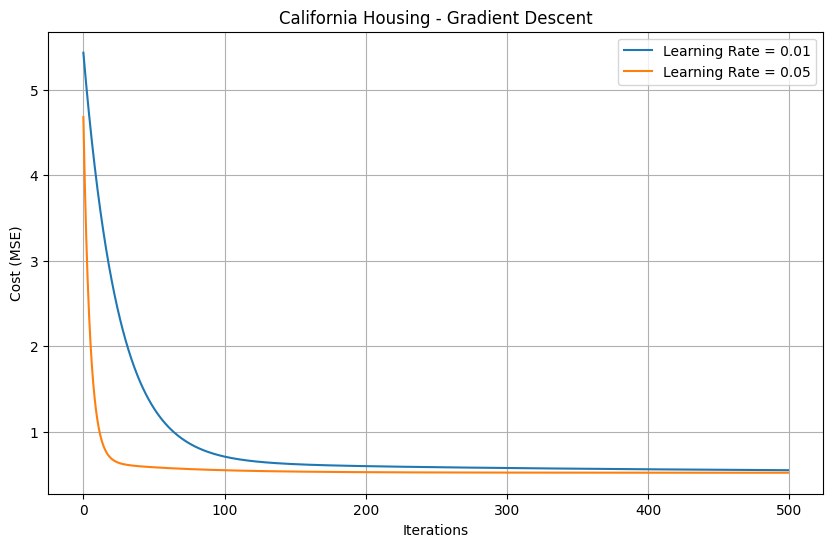

In [ ]:
#sheet 2.3
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset
housing = fetch_california_housing()

X = housing.data
y = housing.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Add bias column
X_train_b = np.c_[np.ones(len(X_train)), X_train]
X_test_b = np.c_[np.ones(len(X_test)), X_test]

# MSE function
def mse(y, yhat):
    return np.mean((y - yhat) ** 2)

# 1. Normal Equation
theta_normal = np.linalg.pinv(X_train_b) @ y_train

predictions_normal = X_test_b @ theta_normal

print("Normal Equation Test MSE:",
      mse(y_test, predictions_normal))

# 2. Batch Gradient Descent
def gradient_descent(X, y, learning_rate, iterations):
    m = len(y)
    theta = np.zeros(X.shape[1])
    costs = []

    for i in range(iterations):
        predictions = X @ theta
        gradients = (2 / m) * X.T @ (predictions - y)
        theta -= learning_rate * gradients

        costs.append(mse(y, X @ theta))

    return theta, costs

iterations = 500

# Learning rate = 0.01
theta1, costs1 = gradient_descent(
    X_train_b, y_train, 0.01, iterations
)

# Learning rate = 0.05
theta2, costs2 = gradient_descent(
    X_train_b, y_train, 0.05, iterations
)

# Print test MSE
print("Gradient Descent Test MSE (LR=0.01):",
      mse(y_test, X_test_b @ theta1))

print("Gradient Descent Test MSE (LR=0.05):",
      mse(y_test, X_test_b @ theta2))

# 3. Plot Cost

plt.figure(figsize=(10, 6))

plt.plot(costs1, label="Learning Rate = 0.01")
plt.plot(costs2, label="Learning Rate = 0.05")

plt.xlabel("Iterations")
plt.ylabel("Cost (MSE)")
plt.title("California Housing - Gradient Descent")
plt.legend()
plt.grid(True)
plt.show()

